 Mobile Phone Price-Tier Classification
Steps covered:

1. Import Libraries
2. Load Dataset
3. Understand the Dataset
4. Creating the Target Variable
5. Data Cleaning
6. Train/Test Split
7. Feature Scaling
8. Saving the Scaler
9. Train Multiple Models & Compare
10. Best Model Selection
11. Model Evaluation (Confusion Matrix, ROC & Accuracy)
12. Final Results Summary



## 1: Import Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, auc, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB



## 2: Load Dataset

In [ ]:
df = pd.read_csv("../data/raw/mobile.csv")
print(df.shape)
df.head()

(1000, 21)


,id,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,...,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi
0,1,1043,1,1.8,1,14,0,5,0.1,193,...,16,226,1412,3476,12,7,2,0,1,0
1,2,841,1,0.5,1,4,1,61,0.8,191,...,12,746,857,3895,6,0,7,1,0,0
2,3,1807,1,2.8,0,1,0,27,0.9,186,...,4,1270,1366,2396,17,10,10,0,1,1
3,4,1546,0,0.5,1,18,1,25,0.5,96,...,20,295,1752,3893,10,0,7,1,1,0
4,5,1434,0,1.4,0,11,1,49,0.5,108,...,18,749,810,1773,15,8,7,1,0,1


## 3: Understand the Dataset

In [3]:
df.info()
print("\nNulls:\n", df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             1000 non-null   int64  
 1   battery_power  1000 non-null   int64  
 2   blue           1000 non-null   int64  
 3   clock_speed    1000 non-null   float64
 4   dual_sim       1000 non-null   int64  
 5   fc             1000 non-null   int64  
 6   four_g         1000 non-null   int64  
 7   int_memory     1000 non-null   int64  
 8   m_dep          1000 non-null   float64
 9   mobile_wt      1000 non-null   int64  
 10  n_cores        1000 non-null   int64  
 11  pc             1000 non-null   int64  
 12  px_height      1000 non-null   int64  
 13  px_width       1000 non-null   int64  
 14  ram            1000 non-null   int64  
 15  sc_h           1000 non-null   int64  
 16  sc_w           1000 non-null   int64  
 17  talk_time      1000 non-null   int64  
 18  three_g  

## 4: Creating the Target Variable

In [ ]:

np.random.seed(42)
resolution = df["px_height"] * df["px_width"]

score = (
    (df["ram"] - df["ram"].mean()) / df["ram"].std()
    + (df["battery_power"] - df["battery_power"].mean()) / df["battery_power"].std()
    + (resolution - resolution.mean()) / resolution.std()
    + (df["int_memory"] - df["int_memory"].mean()) / df["int_memory"].std()
)
noisy_score = score + np.random.normal(0, 1.0, size=len(score))
df["target"] = (noisy_score >= np.median(noisy_score)).astype(int)
print(df["target"].value_counts())

target
0    500
1    500
Name: count, dtype: int64


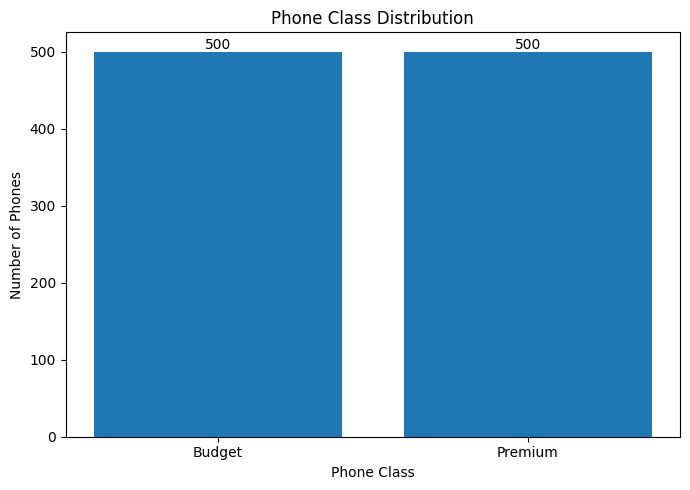

In [ ]:
target_counts = df["target"].value_counts()
labels = ["Budget", "Premium"]
plt.figure(figsize=(7, 5))
bars = plt.bar(labels, [target_counts.get(0, 0), target_counts.get(1, 0)])
plt.title("Phone Class Distribution")
plt.xlabel("Phone Class")
plt.ylabel("Number of Phones")
for bar in bars:
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
              str(int(bar.get_height())), ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 5: Data Cleaning

In [6]:
df = df.drop(columns=["id"])
print(df.columns.tolist())

['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g', 'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height', 'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g', 'touch_screen', 'wifi', 'target']


## 6: Train/Test Split

In [7]:
X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(800, 20) (200, 20)


## 7: Feature Scaling

In [ ]:

X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_train.median())

scaler = StandardScaler()
X_train_final = scaler.fit_transform(X_train)
X_test_final = scaler.transform(X_test)
print(X_train_final.shape, X_test_final.shape)

(800, 20) (200, 20)


## 8: Saving the Scaler

In [9]:
Path("models").mkdir(parents=True, exist_ok=True)
joblib.dump(scaler, "models/scaler.pkl")

['models/scaler.pkl']

## 9: Train Multiple Models & Compare

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42),
    "Naive Bayes": GaussianNB()
}

In [11]:
def evaluate_model(model, model_name):
    y_pred = model.predict(X_test_final)
    y_proba = model.predict_proba(X_test_final)[:, 1]

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)

    print("\n" + model_name)
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1 Score :", round(f1, 4))
    print("ROC-AUC  :", round(roc_auc, 4))

    return {
        "Accuracy": accuracy, "Precision": precision, "Recall": recall,
        "F1": f1, "ROC_AUC": roc_auc, "fpr": fpr, "tpr": tpr
    }

In [12]:
metrics_results, trained_models, roc_data = {}, {}, {}

for model_name, model in models.items():
    model.fit(X_train_final, y_train)
    result = evaluate_model(model, model_name)

    metrics_results[model_name] = {
        "Accuracy": result["Accuracy"], "Precision": result["Precision"],
        "Recall": result["Recall"], "F1": result["F1"], "ROC_AUC": result["ROC_AUC"]
    }
    roc_data[model_name] = {"fpr": result["fpr"], "tpr": result["tpr"], "auc": result["ROC_AUC"]}
    trained_models[model_name] = model


Logistic Regression
Accuracy : 0.84
Precision: 0.8208
Recall   : 0.87
F1 Score : 0.8447
ROC-AUC  : 0.9343

Decision Tree
Accuracy : 0.775
Precision: 0.7477
Recall   : 0.83
F1 Score : 0.7867
ROC-AUC  : 0.7868

Random Forest
Accuracy : 0.835
Precision: 0.819
Recall   : 0.86
F1 Score : 0.839
ROC-AUC  : 0.9319

SVM
Accuracy : 0.84
Precision: 0.8148
Recall   : 0.88
F1 Score : 0.8462
ROC-AUC  : 0.9205

K-Nearest Neighbors
Accuracy : 0.73
Precision: 0.7447
Recall   : 0.7
F1 Score : 0.7216
ROC-AUC  : 0.7864

Gradient Boosting
Accuracy : 0.865
Precision: 0.8476
Recall   : 0.89
F1 Score : 0.8683
ROC-AUC  : 0.9404

AdaBoost
Accuracy : 0.835
Precision: 0.8252
Recall   : 0.85
F1 Score : 0.8374
ROC-AUC  : 0.917

Naive Bayes
Accuracy : 0.845
Precision: 0.8485
Recall   : 0.84
F1 Score : 0.8442
ROC-AUC  : 0.9193


In [13]:
results_df = pd.DataFrame(metrics_results).T
results_df = results_df.sort_values(by="F1", ascending=False)
print(results_df)

                     Accuracy  Precision  Recall        F1  ROC_AUC
Gradient Boosting       0.865   0.847619    0.89  0.868293  0.94040
SVM                     0.840   0.814815    0.88  0.846154  0.92050
Logistic Regression     0.840   0.820755    0.87  0.844660  0.93430
Naive Bayes             0.845   0.848485    0.84  0.844221  0.91930
Random Forest           0.835   0.819048    0.86  0.839024  0.93190
AdaBoost                0.835   0.825243    0.85  0.837438  0.91700
Decision Tree           0.775   0.747748    0.83  0.786730  0.78680
K-Nearest Neighbors     0.730   0.744681    0.70  0.721649  0.78645


## 10: Best Model Selection

In [14]:
best_model_name = results_df["F1"].idxmax()
best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print(results_df.loc[best_model_name])

Best Model: Gradient Boosting
Accuracy     0.865000
Precision    0.847619
Recall       0.890000
F1           0.868293
ROC_AUC      0.940400
Name: Gradient Boosting, dtype: float64


In [15]:
joblib.dump(best_model, "models/best_model.pkl")

['models/best_model.pkl']

## 11: Model Evaluation (Confusion Matrix, ROC & Accuracy)

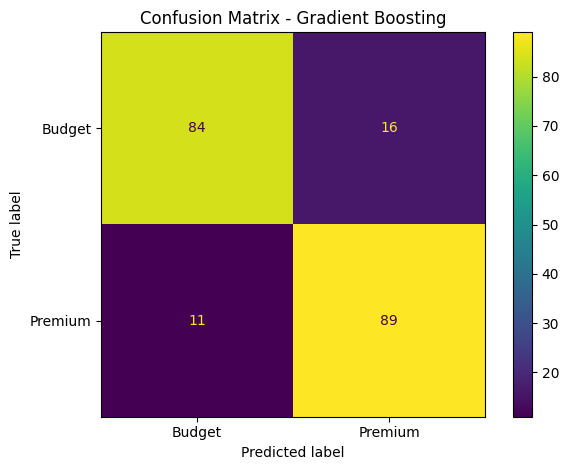

In [16]:
best_predictions = best_model.predict(X_test_final)

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions, display_labels=["Budget", "Premium"]
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

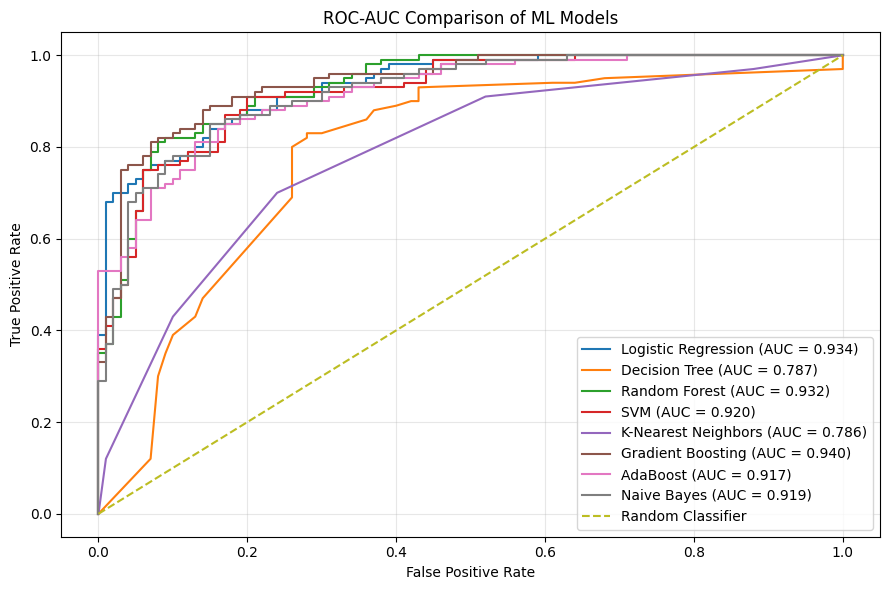

In [17]:
plt.figure(figsize=(9, 6))
for model_name, data in roc_data.items():
    plt.plot(data["fpr"], data["tpr"], label=f"{model_name} (AUC = {data['auc']:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Comparison of ML Models")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

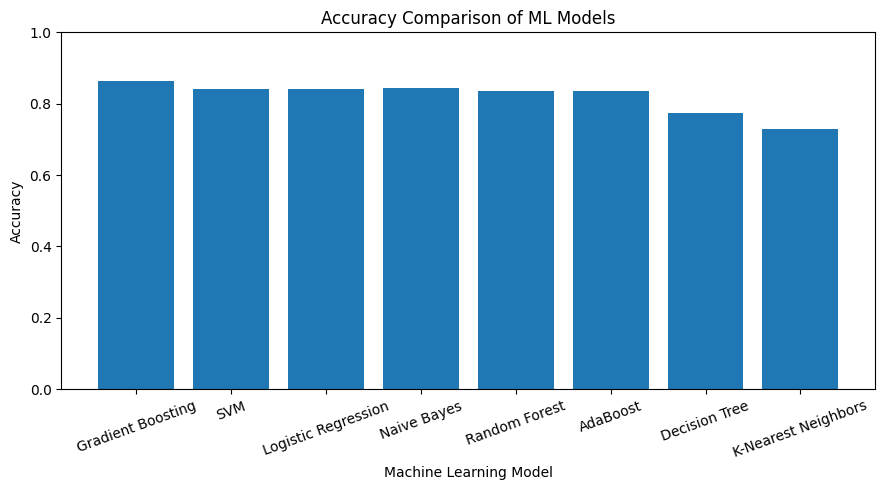

In [18]:
plt.figure(figsize=(9, 5))
plt.bar(results_df.index, results_df["Accuracy"])
plt.title("Accuracy Comparison of ML Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [19]:
Path("outputs").mkdir(parents=True, exist_ok=True)
results_df.to_csv("outputs/model_comparison.csv")

## 12: Final Results Summary

In [20]:
print("=" * 50)
print("FINAL MODEL RESULT")
print("=" * 50)
print("Best Model:", best_model_name)
print("Accuracy:", f"{results_df.loc[best_model_name, 'Accuracy'] * 100:.2f}%")
print("Precision:", f"{results_df.loc[best_model_name, 'Precision'] * 100:.2f}%")
print("Recall:", f"{results_df.loc[best_model_name, 'Recall'] * 100:.2f}%")
print("F1 Score:", f"{results_df.loc[best_model_name, 'F1'] * 100:.2f}%")
print("ROC-AUC:", f"{results_df.loc[best_model_name, 'ROC_AUC'] * 100:.2f}%")

FINAL MODEL RESULT
Best Model: Gradient Boosting
Accuracy: 86.50%
Precision: 84.76%
Recall: 89.00%
F1 Score: 86.83%
ROC-AUC: 94.04%
